# Рекомендательная система фильмов

## Постановка задачи

Сделать рекомендательную систему фильмов и API к ней. API должен отдавать приложению:

1. список топ-10 популярных фильмов;
2. рекомендации на основе коллаборативной фильтрации (по пользователям и по фильмам);
3. список 10 рекомендованных фильмов по контенту;
4. персональные рекомендации для определённого пользователя.

Потом сделать приложение с графическим интерфейсом, которое через API показывает эти списки. Данные хранятся в БД, в приложении можно выбрать фильм и оценить его, есть справка по командам и их параметрам.

Данные: открытый датасет онлайн-кинотеатра Kion от МТС (MTS Kion, просмотры за март-август 2021 года). Названия, жанры и описания фильмов в нём сразу на русском.

## Этап 1. Исследование данных (EDA)

### 1.1 Знакомство с данными

Загружаем два файла: каталог `kion_items.csv` и просмотры `kion_interactions.csv.gz`. Смотрим размер, первые и последние строки и одну случайную строку.

In [1]:
# библиотеки для работы с данными и графиками
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_colwidth', 60)

In [2]:
# читаем каталог из папки data
items = pd.read_csv('../data/kion_items.csv')
print("Размер каталога (строк, столбцов):", items.shape)

# первые 5 строк
items.head()

Размер каталога (строк, столбцов): (15963, 14)


,item_id,content_type,title,title_orig,release_year,genres,countries,for_kids,age_rating,studios,directors,actors,description,keywords
0,10711,film,Поговори с ней,Hable con ella,2002.0,"драмы, зарубежные, детективы, мелодрамы",Испания,NaN,16.0,NaN,Педро Альмодовар,"Адольфо Фернандес, Ана Фернандес, Дарио Грандинетти, Дже...",Мелодрама легендарного Педро Альмодовара «Поговори с ней...,"Поговори, ней, 2002, Испания, друзья, любовь, сильные, ж..."
1,2508,film,Голые перцы,Search Party,2014.0,"зарубежные, приключения, комедии",США,NaN,16.0,NaN,Скот Армстронг,"Адам Палли, Брайан Хаски, Дж.Б. Смув, Джейсон Манцукас, ...",Уморительная современная комедия на популярную тему о то...,"Голые, перцы, 2014, США, друзья, свадьбы, преодоление, т..."
2,10716,film,Тактическая сила,Tactical Force,2011.0,"криминал, зарубежные, триллеры, боевики, комедии",Канада,NaN,16.0,NaN,Адам П. Калтраро,"Адриан Холмс, Даррен Шалави, Джерри Вассерман, Дэн Риззу...",Профессиональный рестлер Стив Остин («Все или ничего») и...,"Тактическая, сила, 2011, Канада, бандиты, гангстеры, пре..."
3,7868,film,45 лет,45 Years,2015.0,"драмы, зарубежные, мелодрамы",Великобритания,NaN,16.0,NaN,Эндрю Хэй,"Александра Риддлстон-Барретт, Джеральдин Джеймс, Долли У...","Шарлотта Рэмплинг, Том Кортни, Джеральдин Джеймс и Долли...","45, лет, 2015, Великобритания, брак, жизнь, любовь, псих..."
4,16268,film,Все решает мгновение,NaN,1978.0,"драмы, спорт, советские, мелодрамы",СССР,NaN,12.0,Ленфильм,Виктор Садовский,"Александр Абдулов, Александр Демьяненко, Алексей Василье...",Расчетливая чаровница из советского кинохита «Мой ласков...,"Все, решает, мгновение, 1978, СССР, сильные, женщины, сп..."


In [3]:
# последние 5 строк
items.tail()

,item_id,content_type,title,title_orig,release_year,genres,countries,for_kids,age_rating,studios,directors,actors,description,keywords
15958,6443,series,Полярный круг,Arctic Circle,2018.0,"драмы, триллеры, криминал","Финляндия, Германия",NaN,16.0,NaN,Ханну Салонен,"Иина Куустонен, Максимилиан Брюкнер, Пихла Виитала, Суса...","Во время погони за браконьерами по лесу, сотрудница финс...","убийство, вирус, расследование преступления, нордический..."
15959,2367,series,Надежда,NaN,2020.0,"драмы, боевики",Россия,0.0,18.0,NaN,Елена Хазанова,"Виктория Исакова, Александр Кузьмин, Алексей Морозов, Ве...",Оригинальный киносериал от создателей «Бывших». Дома она...,"Надежда, 2020, Россия"
15960,10632,series,Сговор,Hassel,2017.0,"драмы, триллеры, криминал",Россия,0.0,18.0,NaN,"Эшреф Рейбрук, Амир Камдин, Эрик Эгер","Ола Рапас, Алиетт Офейм, Уильма Лиден, Шанти Рони, Тома ...",Криминальная драма по мотивам романов о шведском детекти...,"Сговор, 2017, Россия"
15961,4538,series,Среди камней,Darklands,2019.0,"драмы, спорт, криминал",Россия,0.0,18.0,NaN,"Марк О’Коннор, Конор МакМахон","Дэйн Уайт О’Хара, Томас Кэйн-Бирн, Джудит Родди, Марк О’...",Семнадцатилетний Дэмиен мечтает вырваться за пределы сво...,"Среди, камней, 2019, Россия"
15962,3206,series,Гоша,NaN,2019.0,комедии,Россия,0.0,16.0,NaN,Михаил Миронов,"Мкртыч Арзуманян, Виктория Рунцова","Добродушный Гоша не может выйти из дома, чтобы не попаст...","Гоша, 2019, Россия"


In [4]:
# одна случайная строка
items.sample(1, random_state=42)

,item_id,content_type,title,title_orig,release_year,genres,countries,for_kids,age_rating,studios,directors,actors,description,keywords
11914,10021,series,История искусств вместе с Хрюшей и...,NaN,2012.0,"русские, познавательные, для детей, хочу всё знать",Россия,NaN,0.0,NaN,Елена Лезина,"Артем Кретов, Наталья Голубенцева, Оксана Чабанюк, Серге...",Путешествие в прекрасный мир искусства вместе с героями ...,"История, искусств, вместе, Хрюшей, 2012, Россия, гении, ..."


### Описание признаков каталога (по описанию датасета MTS Kion)

1. item_id: id фильма или сериала;
2. content_type: тип, film (фильм) или series (сериал);
3. title: название на русском;
4. title_orig: оригинальное название;
5. release_year: год выхода;
6. genres: жанры через запятую;
7. countries: страны;
8. for_kids: флаг детского контента;
9. age_rating: возрастной рейтинг;
10. studios: студии;
11. directors: режиссёры;
12. actors: актёры;
13. description: описание на русском;
14. keywords: теги каталога.

In [5]:
# типы данных и количество непустых значений
items.info()

<class 'pandas.DataFrame'>
RangeIndex: 15963 entries, 0 to 15962
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   item_id       15963 non-null  int64  
 1   content_type  15963 non-null  str    
 2   title         15963 non-null  str    
 3   title_orig    11218 non-null  str    
 4   release_year  15865 non-null  float64
 5   genres        15963 non-null  str    
 6   countries     15926 non-null  str    
 7   for_kids      566 non-null    float64
 8   age_rating    15961 non-null  float64
 9   studios       1065 non-null   str    
 10  directors     14454 non-null  str    
 11  actors        13344 non-null  str    
 12  description   15961 non-null  str    
 13  keywords      15540 non-null  str    
dtypes: float64(3), int64(1), str(10)
memory usage: 31.5 MB


В каталоге 15 963 записи и 14 столбцов. Почти все столбцы текстовые, числовые только item_id, release_year, for_kids и age_rating. Пропуски видно по Non-Null Count: больше всего их в for_kids и studios, у description пропущено всего 2 значения.

In [6]:
# читаем просмотры, pandas сам распаковывает gz
inter = pd.read_csv('../data/kion_interactions.csv.gz')
print("Размер таблицы просмотров (строк, столбцов):", inter.shape)

# первые 5 строк
inter.head()

Размер таблицы просмотров (строк, столбцов): (5476251, 5)


,user_id,item_id,last_watch_dt,total_dur,watched_pct
0,176549,9506,2021-05-11,4250,72.0
1,699317,1659,2021-05-29,8317,100.0
2,656683,7107,2021-05-09,10,0.0
3,864613,7638,2021-07-05,14483,100.0
4,964868,9506,2021-04-30,6725,100.0


### Описание признаков просмотров

1. user_id: id пользователя;
2. item_id: id фильма или сериала;
3. last_watch_dt: дата последнего просмотра;
4. total_dur: сколько секунд пользователь смотрел контент всего;
5. watched_pct: какую часть контента посмотрел, %.

Оценок от пользователей (например, от 1 до 10) в датасете нет, есть только просмотры. Оценку получим из доли просмотра на этапе 2.

In [7]:
# типы данных и количество непустых значений
inter.info()

<class 'pandas.DataFrame'>
RangeIndex: 5476251 entries, 0 to 5476250
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   user_id        int64  
 1   item_id        int64  
 2   last_watch_dt  str    
 3   total_dur      int64  
 4   watched_pct    float64
dtypes: float64(1), int64(3), str(1)
memory usage: 261.1 MB


В таблице просмотров 5 476 251 строка. Дата хранится строкой, total_dur целое число секунд, watched_pct дробное.

### 1.2 Описательная статистика

In [8]:
# статистика по числовым столбцам просмотров
inter[['total_dur', 'watched_pct']].describe()

,total_dur,watched_pct
count,5.476251e+06,5.475423e+06
mean,8.295490e+03,4.637400e+01
std,4.856799e+04,4.191853e+01
min,1.000000e+00,0.000000e+00
25%,3.710000e+02,4.000000e+00
50%,2.898000e+03,3.200000e+01
75%,7.116000e+03,1.000000e+02
max,8.041167e+07,1.000000e+02


По числовым признакам просмотров:

1. total_dur: медиана 2 898 секунд (около 48 минут), но максимум 80 411 670 секунд, значит, у части пользователей время копилось за много повторных просмотров.
2. watched_pct: медиана 32%, а четверть просмотров не дошла и до 4%. Много людей включают фильм и сразу закрывают.
3. В watched_pct есть пропуски: count меньше числа строк.

In [9]:
# статистика по текстовым столбцам каталога
items[['content_type', 'title', 'genres', 'countries', 'directors']].describe()

,content_type,title,genres,countries,directors
count,15963,15963,15963,15926,14454
unique,2,15293,2771,687,7973
top,film,Охота,документальное,Россия,Оливье Шиабоду
freq,12002,5,816,4237,511


По текстовым столбцам каталога:

1. content_type: 2 значения, фильмов 12 002.
2. title: уникальных названий 15 293 из 15 963, то есть часть названий повторяется (ремейки, копии в 4К).
3. genres: 2 771 разная комбинация жанров, чаще всего встречается «документальное».
4. countries: чаще всего Россия (4 237 записей).

In [10]:
# сколько пользователей, фильмов и просмотров
views_per_user = inter.groupby('user_id').size()
print(f"Пользователей: {inter['user_id'].nunique():,}")
print(f"Фильмов и сериалов с просмотрами: {inter['item_id'].nunique():,}")
print(f"Медиана просмотров на пользователя: {views_per_user.median():.0f}")
print(f"Пользователей с 20 и больше просмотрами: {(views_per_user >= 20).sum():,}")

Пользователей: 962,179
Фильмов и сериалов с просмотрами: 15,706
Медиана просмотров на пользователя: 2
Пользователей с 20 и больше просмотрами: 54,014


Пользователей 962 179, но у половины из них всего 2 просмотра. Пользователей с 20 и больше просмотрами 54 014, коллаборативную фильтрацию имеет смысл строить по ним.

### 1.3 Визуальный анализ

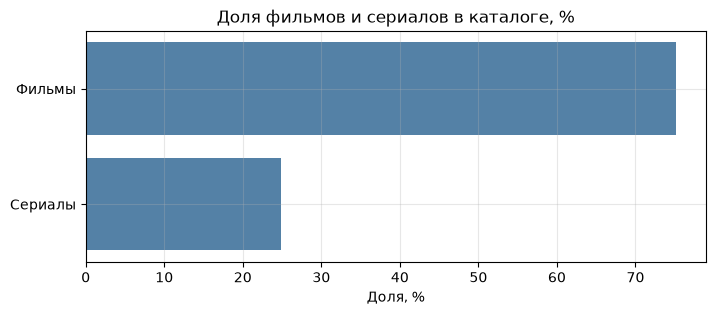

In [11]:
# 1. доли фильмов и сериалов в каталоге
type_share = items['content_type'].value_counts(normalize=True) * 100

plt.figure(figsize=(8, 3))
sns.barplot(x=type_share.values, y=type_share.index.map({'film': 'Фильмы', 'series': 'Сериалы'}), color='steelblue')
plt.title('Доля фильмов и сериалов в каталоге, %')
plt.xlabel('Доля, %')
plt.ylabel('')
plt.grid(True, alpha=0.3)
plt.show()

Фильмов около 75%, сериалов около 25%. Фильмов достаточно, сериалы дальше уберём.

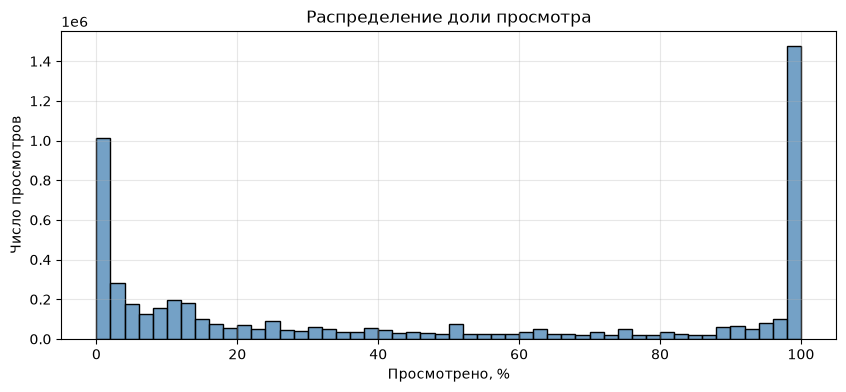

In [12]:
# 2. распределение доли просмотра
plt.figure(figsize=(10, 4))
sns.histplot(inter['watched_pct'].dropna(), bins=50, color='steelblue')
plt.title('Распределение доли просмотра')
plt.xlabel('Просмотрено, %')
plt.ylabel('Число просмотров')
plt.grid(True, alpha=0.3)
plt.show()

Распределение доли просмотра с двумя пиками: 27% просмотров дошли не дальше 5%, а 30% досмотрены на 95% и больше. Середина заполнена слабо: обычно фильм либо бросают в самом начале, либо смотрят до конца.

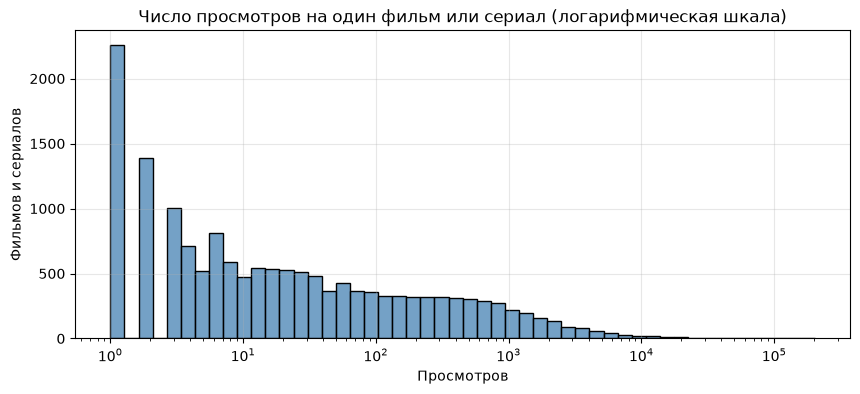

Медиана просмотров: 12, максимум: 202,457


In [13]:
# 3. сколько просмотров у одного фильма или сериала
views_per_item = inter.groupby('item_id').size()

plt.figure(figsize=(10, 4))
sns.histplot(views_per_item, bins=50, log_scale=True, color='steelblue')
plt.title('Число просмотров на один фильм или сериал (логарифмическая шкала)')
plt.xlabel('Просмотров')
plt.ylabel('Фильмов и сериалов')
plt.grid(True, alpha=0.3)
plt.show()

print(f"Медиана просмотров: {views_per_item.median():.0f}, максимум: {views_per_item.max():,}")

Медиана всего 12 просмотров на фильм или сериал, а максимум 202 457. У 37% контента не больше 5 просмотров. По таким редким фильмам похожих по оценкам не найти, поэтому оставим только фильмы с большим числом просмотров.

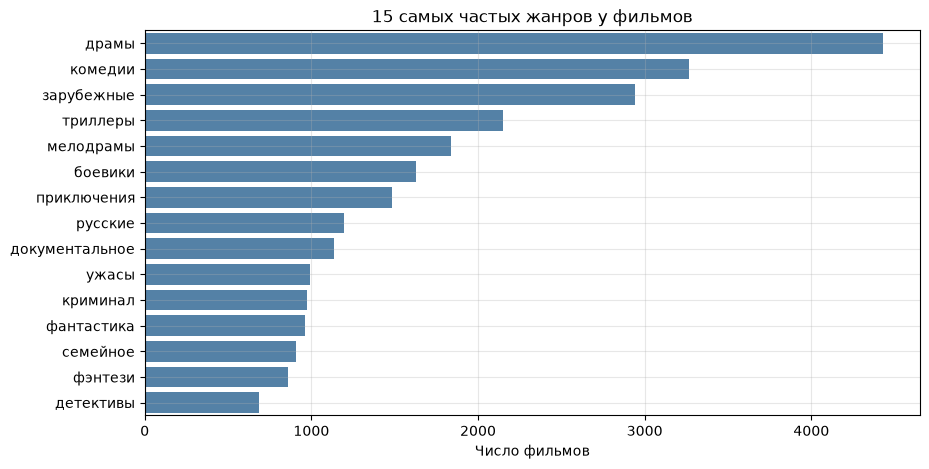

In [14]:
# 4. самые частые жанры у фильмов
films_all = items[items['content_type'] == 'film']
genre_counts = films_all['genres'].str.split(', ').explode().value_counts().head(15)

plt.figure(figsize=(10, 5))
sns.barplot(x=genre_counts.values, y=genre_counts.index, color='steelblue')
plt.title('15 самых частых жанров у фильмов')
plt.xlabel('Число фильмов')
plt.ylabel('')
plt.grid(True, alpha=0.3)
plt.show()

Чаще всего встречаются драмы (4 429 фильмов), комедии (3 264) и триллеры (2 151). «Зарубежные» и «русские» это не жанры, а пометки каталога, но они тоже помогают находить похожие фильмы.

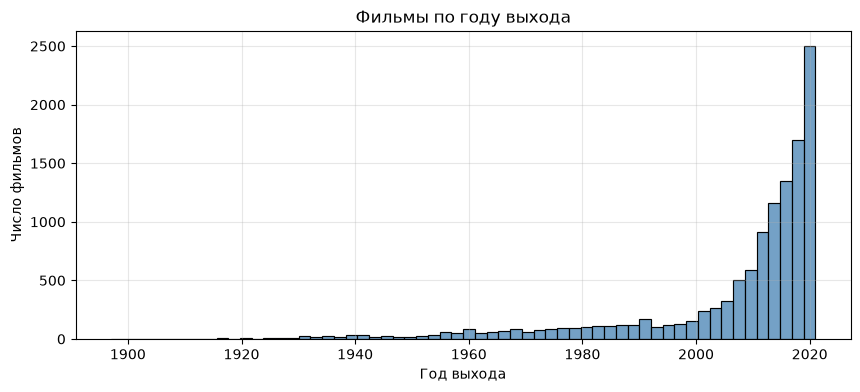

In [15]:
# 5. фильмы по году выхода
plt.figure(figsize=(10, 4))
sns.histplot(films_all['release_year'].dropna(), bins=60, color='steelblue')
plt.title('Фильмы по году выхода')
plt.xlabel('Год выхода')
plt.ylabel('Число фильмов')
plt.grid(True, alpha=0.3)
plt.show()

Каталог в основном из новых фильмов: 66% вышли в 2010 году и позже, до 1980 года меньше 10%. Самый поздний год 2021.

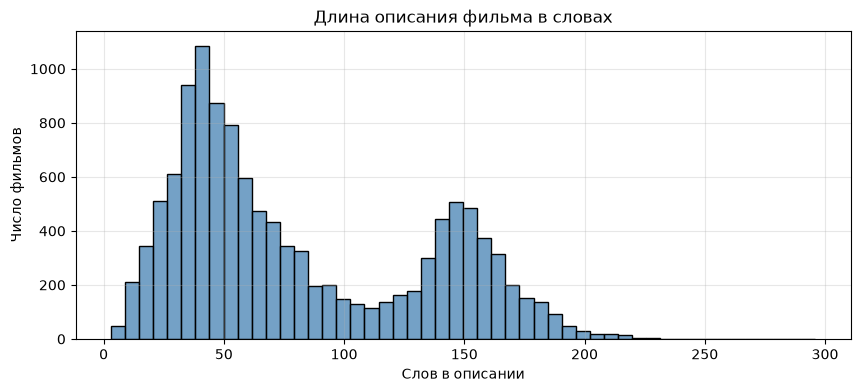

Медиана длины описания: 61 слов


In [16]:
# 6. длина описания в словах
desc_words = films_all['description'].str.split().str.len()

plt.figure(figsize=(10, 4))
sns.histplot(desc_words, bins=50, color='steelblue')
plt.title('Длина описания фильма в словах')
plt.xlabel('Слов в описании')
plt.ylabel('Число фильмов')
plt.grid(True, alpha=0.3)
plt.show()

print(f"Медиана длины описания: {desc_words.median():.0f} слов")

Медиана длины описания 61 слово. Видно два пика: короткие описания около 40 слов и длинные около 150 слов (31% описаний длиннее 110 слов). Текста хватает, чтобы сравнивать фильмы по описанию.

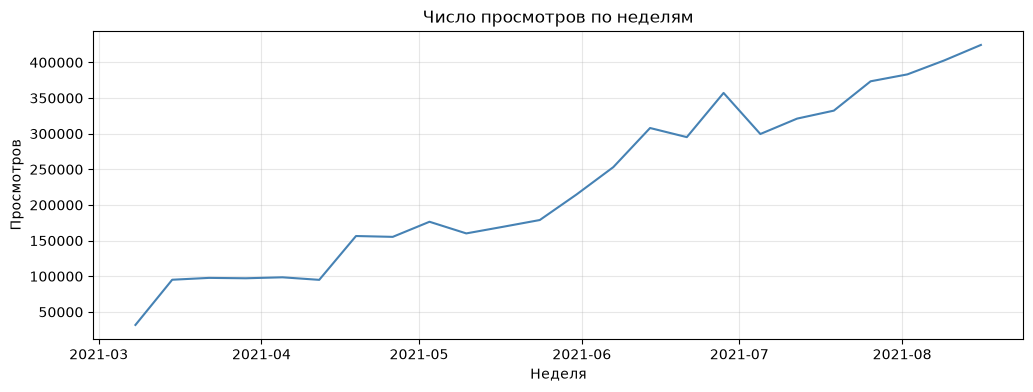

In [17]:
# 7. число просмотров по неделям
week_views = pd.to_datetime(inter['last_watch_dt']).dt.to_period('W').dt.start_time.value_counts().sort_index()

plt.figure(figsize=(12, 4))
plt.plot(week_views.index, week_views.values, color='steelblue')
plt.title('Число просмотров по неделям')
plt.xlabel('Неделя')
plt.ylabel('Просмотров')
plt.grid(True, alpha=0.3)
plt.show()

Число просмотров за неделю выросло примерно с 95 тысяч в марте до 424 тысяч в августе (первая неделя неполная). Сервис рос, поэтому новые фильмы 2021 года набрали больше всего просмотров.

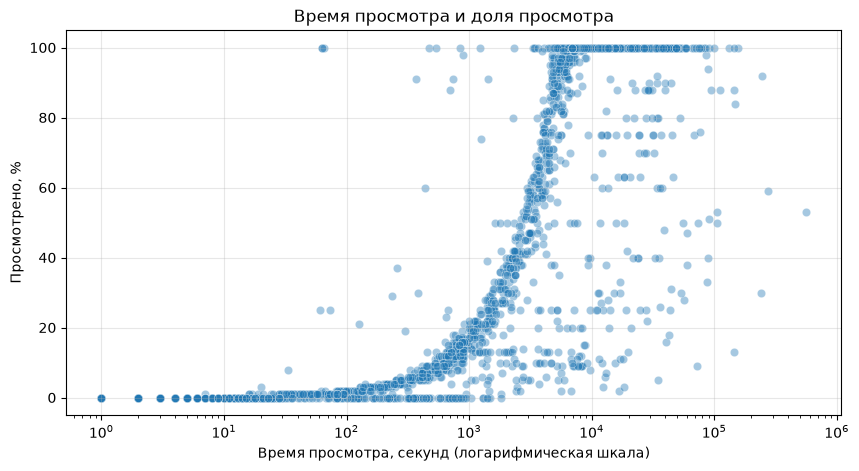

In [18]:
# 8. доля просмотра и время просмотра на случайных 2000 строках
sample_inter = inter.sample(2000, random_state=42)

plt.figure(figsize=(10, 5))
sns.scatterplot(data=sample_inter, x='total_dur', y='watched_pct', alpha=0.4)
plt.xscale('log')
plt.title('Время просмотра и доля просмотра')
plt.xlabel('Время просмотра, секунд (логарифмическая шкала)')
plt.ylabel('Просмотрено, %')
plt.grid(True, alpha=0.3)
plt.show()

Пока время просмотра меньше нескольких минут, доля просмотра почти всегда около нуля. Дальше она растёт и после 1-2 часов упирается в 100%. Точки справа ниже 100%, скорее всего, сериалы: их смотрят часами, но не до конца.

### 1.4 Пропуски, дубликаты, аномалии

In [19]:
# таблица пропусков в каталоге
null_info = pd.DataFrame({
    'Пропусков': items.isna().sum(),
    'Процент': (items.isna().sum() / len(items) * 100).round(2)
})
null_info[null_info['Пропусков'] > 0].sort_values('Процент', ascending=False)

,Пропусков,Процент
for_kids,15397,96.45
studios,14898,93.33
title_orig,4745,29.72
actors,2619,16.41
directors,1509,9.45
keywords,423,2.65
release_year,98,0.61
countries,37,0.23
age_rating,2,0.01
description,2,0.01


Почти пустые for_kids (96.45%) и studios (93.33%), они нам не нужны. Нужные для рекомендаций title, genres и description почти без пропусков, у release_year пропущено 0.61%.

In [20]:
# пропуски, повторы и странные значения в просмотрах
print("Пропусков в просмотрах:", inter.isna().sum().sum())
print("Повторных пар пользователь-фильм:", inter.duplicated(['user_id', 'item_id']).sum())
print("Доля просмотра больше 100%:", (inter['watched_pct'] > 100).sum())
print(f"Просмотров короче 5 минут: {(inter['total_dur'] < 300).mean() * 100:.1f}%")
print("Просмотров контента, которого нет в каталоге:", (~inter['item_id'].isin(items['item_id'])).sum())

Пропусков в просмотрах: 828


Повторных пар пользователь-фильм: 0
Доля просмотра больше 100%: 0
Просмотров короче 5 минут: 23.4%
Просмотров контента, которого нет в каталоге: 0


Пропуски в просмотрах только в watched_pct (828 строк). Повторов пар пользователь-фильм нет, доли больше 100% нет, весь контент из просмотров есть в каталоге. Просмотров короче 5 минут 23.4%.

### 1.5 Гипотезы

**Гипотеза 1.** У просмотров короче 5 минут доля просмотра обычно близка к нулю.

**Гипотеза 2.** Описаний (медиана 61 слово) хватает, чтобы находить похожие фильмы: у фильмов, похожих по описанию, жанры будут совпадать чаще, чем у случайных пар.

**Гипотеза 3.** Прогноз по похожим пользователям и похожим фильмам будет точнее, чем простая средняя оценка фильма.

## Этап 2. Предварительная обработка данных

Что делаем:

1. 2.1 Оставляем в каталоге только фильмы и нужные столбцы.
2. 2.2 Убираем короткие просмотры, редкие фильмы и малоактивных пользователей.
3. 2.3 Переводим долю просмотра в оценку от 1 до 10.
4. 2.4 Готовим описания для TF-IDF.
5. 2.5 Сохраняем каталог и оценки для приложения.
6. 2.6 Делим оценки на обучающую и тестовую часть для проверки качества.

### 2.1 Каталог фильмов

1. Сериалы убираем: в задании речь про фильмы, и долю просмотра сериала сложно сравнивать с фильмом.
2. Для рекомендаций нужны id, название, жанры, год и описание. Остальные столбцы (актёры, студии, страны) не используем.
3. Копии фильмов в качестве 4К (название начинается с «[4К]» или «[4k]») убираем: это тот же фильм, и в похожих по контенту он стоял бы первым.
4. Длинные и средние тире в названиях и описаниях меняем на обычный дефис, так текст выглядит одинаково во всём приложении.
5. Столбцы переименовываем так, как их ждёт приложение: movie_id, title, genres, year, overview.

In [21]:
# только фильмы и нужные столбцы
movies = items[items['content_type'] == 'film'][['item_id', 'title', 'genres', 'release_year', 'description']].copy()
movies = movies.rename(columns={'item_id': 'movie_id', 'release_year': 'year', 'description': 'overview'})

# год без пропусков переводим в целое число
before_year = len(movies)
movies = movies.dropna(subset=['year'])
movies['year'] = movies['year'].astype(int)
movies['overview'] = movies['overview'].str.strip()

# тире в текстах меняем на дефис
for col in ['title', 'overview']:
    movies[col] = movies[col].str.replace('[\u2014\u2013]', '-', regex=True)
print(f"Фильмов в каталоге: {before_year:,}, удалено без года: {before_year - len(movies)}")

# убираем копии в 4К
copies_4k = movies['title'].str.lower().str.startswith(('[4к]', '[4k]'))
movies = movies[~copies_4k]
print(f"Удалено копий в 4К: {copies_4k.sum()}, осталось фильмов: {len(movies):,}")

Фильмов в каталоге: 12,002, удалено без года: 25
Удалено копий в 4К: 387, осталось фильмов: 11,590


Из 12 002 фильмов удалили 25 без года и 387 копий в 4К, осталось 11 590 фильмов.

### 2.2 Отбор просмотров

1. Просмотры короче 5 минут убираем: по ним мало информации о том, досмотрел бы пользователь фильм.
2. Оставляем фильмы, у которых не меньше 300 просмотров: по редким фильмам коллаборативная фильтрация не найдёт похожих.
3. Оставляем пользователей, у которых не меньше 20 просмотров среди этих фильмов, и случайно берём 4 000 из них. Так матрица оценок помещается в память и считается за секунды.

In [22]:
# просмотры только фильмов и не короче 5 минут
inter_films = inter[inter['item_id'].isin(movies['movie_id'])]
inter_clean = inter_films[inter_films['total_dur'] >= 300]
print(f"Просмотров фильмов: {len(inter_films):,}, после удаления коротких: {len(inter_clean):,}")

# фильмы с 300 и больше просмотрами
film_views = inter_clean['item_id'].value_counts()
popular_ids = film_views[film_views >= 300].index
inter_clean2 = inter_clean[inter_clean['item_id'].isin(popular_ids)]
print(f"Фильмов с 300 и больше просмотрами: {len(popular_ids):,}")

# активные пользователи и случайная выборка из 4000
user_views = inter_clean2['user_id'].value_counts()
active_users = user_views[user_views >= 20].index.to_series()
sample_users = active_users.sample(4000, random_state=42)
inter_clean3 = inter_clean2[inter_clean2['user_id'].isin(sample_users)]
print(f"Активных пользователей: {len(active_users):,}, в выборке: {inter_clean3['user_id'].nunique():,}")
print(f"Просмотров в выборке: {len(inter_clean3):,}, фильмов: {inter_clean3['item_id'].nunique():,}")

Просмотров фильмов: 4,113,578, после удаления коротких: 3,149,084


Фильмов с 300 и больше просмотрами: 1,734


Активных пользователей: 23,838, в выборке: 4,000
Просмотров в выборке: 136,161, фильмов: 1,734


После удаления коротких просмотров осталось 3 149 084 из 4 113 578 просмотров фильмов. Гипотеза 1 подтверждается графиком 8: при времени меньше 5 минут доля просмотра почти всегда около нуля.

Фильмов с 300 и больше просмотрами 1 734, активных пользователей 23 838. В выборке 4 000 пользователей и 136 161 просмотр всех 1 734 фильмов.

### 2.3 Балл из доли просмотра

В Kion есть доля просмотра, поэтому используем её как косвенный признак интереса. Делим долю на 10 и округляем вверх, оставляя баллы от 1 до 10. Например, 95% просмотра дают 10, 42% дают 5, 3% дают 1. В приложении пользователь сам ставит оценки на той же шкале.

Пользователей перенумеровываем от 1 до 4 000. Пользователи приложения выбирают ID от 4 001 для своих оценок.

In [23]:
# оценка от 1 до 10
ratings = inter_clean3[['user_id', 'item_id', 'watched_pct']].copy()
ratings['rating'] = np.clip(np.ceil(ratings['watched_pct'] / 10), 1, 10).astype(int)
ratings = ratings.rename(columns={'item_id': 'movie_id'})

# новые id пользователей от 1 до 4000
new_ids = {old_id: i + 1 for i, old_id in enumerate(sorted(ratings['user_id'].unique()))}
ratings['user_id'] = ratings['user_id'].map(new_ids)
ratings = ratings[['user_id', 'movie_id', 'rating']].sort_values(['user_id', 'movie_id']).reset_index(drop=True)
ratings.head()

,user_id,movie_id,rating
0,1,308,10
1,1,849,9
2,1,1053,10
3,1,3784,2
4,1,4495,10


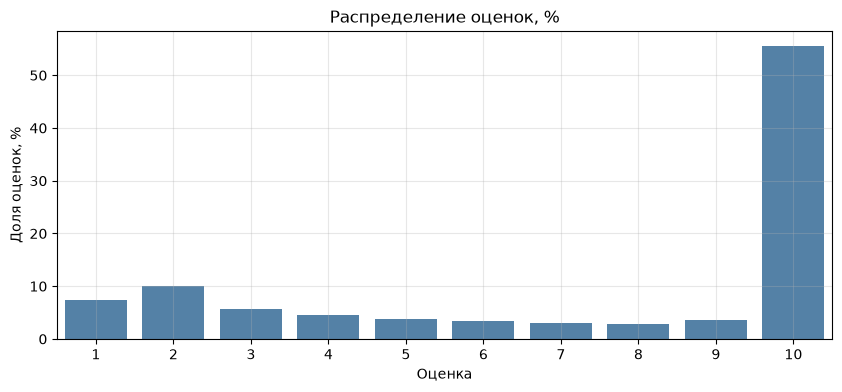

Средняя оценка: 7.35


In [24]:
# распределение оценок
rating_share = ratings['rating'].value_counts(normalize=True).sort_index() * 100

plt.figure(figsize=(10, 4))
sns.barplot(x=rating_share.index, y=rating_share.values, color='steelblue')
plt.title('Распределение оценок, %')
plt.xlabel('Оценка')
plt.ylabel('Доля оценок, %')
plt.grid(True, alpha=0.3)
plt.show()

print(f"Средняя оценка: {ratings['rating'].mean():.2f}")

У 55.6% просмотров балл 10: зритель посмотрел больше 90% фильма. Ещё 17.4% получили 1-2 балла. Средний балл 7.35. Дальше проверим, сколько прогнозов в топе достигают 10.

### 2.4 Подготовка описаний

Для контентной фильтрации описания переводим в вектора TF-IDF. В русском у слова много форм («робот», «робота», «роботы»), поэтому приводим слова к начальной форме через pymorphy3. Предлоги, союзы, частицы, местоимения и слова короче 3 букв убираем, они ничего не говорят о сюжете.

In [25]:
# лемматизация описаний
import re
import pymorphy3

morph = pymorphy3.MorphAnalyzer()
skip_tags = {'PREP', 'CONJ', 'PRCL', 'NPRO', 'INTJ'}
lemma_cache = {}


def prepare_text(text):
    words = re.findall('[а-яё]+', str(text).lower())
    lemmas = []
    for word in words:
        if word not in lemma_cache:
            parsed = morph.parse(word)[0]
            lemma_cache[word] = '' if parsed.tag.POS in skip_tags else parsed.normal_form
        lemma = lemma_cache[word]
        if len(lemma) >= 3:
            lemmas.append(lemma)
    return ' '.join(lemmas)

In [26]:
# оставляем фильмы из выборки и проверяем функцию на одном описании
movies_clean = movies[movies['movie_id'].isin(ratings['movie_id'])].reset_index(drop=True)
print(movies_clean['overview'][0][:300])
print()
print(prepare_text(movies_clean['overview'][0])[:300])

Писатель Морт Рейни живет в доме на берегу. Ещё недавно у него была жена и карьера писателя, сейчас с женой он встречается только для того, чтобы в очередной раз отказаться подписать документы о разводе. С творчеством у Морта тоже не очень гладко, он начинает писать и тут же стирает написанное. Все 

писатель морт рейня жить дом берег ещё недавно быть жена карьера писатель сейчас жена встречаться только тот очередной раз отказаться подписать документ развод творчество морт очень гладко начинать писать тут стирать написать день напролёт морт только спать смотреть экран компьютер этот размеренный 


In [27]:
# готовим текст для всех фильмов
movies_clean['text'] = movies_clean['overview'].apply(prepare_text)
print("Фильмов:", len(movies_clean))
print(f"Медиана слов после обработки: {movies_clean['text'].str.split().str.len().median():.0f}")

Фильмов: 1734
Медиана слов после обработки: 41


Функция приводит слова к начальной форме («живет» стало «жить», «писателя» стало «писатель») и убирает служебные слова. Медиана описания после обработки 41 слово.

### 2.5 Сохранение

Сохраняем каталог и оценки. При первом запуске API переносит их в базу SQLite `data/recommender.sqlite3`, а новые оценки из приложения сохраняются уже в базу.

In [28]:
# сохраняем каталог и оценки для приложения
movies_clean.to_csv('../data/movies.csv', index=False)
ratings.to_csv('../data/ratings.csv', index=False)
print("movies.csv:", movies_clean.shape)
print("ratings.csv:", ratings.shape)

movies.csv: (1734, 6)
ratings.csv: (136161, 3)


### 2.6 Обучающая и тестовая выборки

Чтобы проверить, насколько точно методы угадывают оценку, прячем 20% оценок. Методы считаем по оставшимся 80% и предсказываем спрятанные. Если в тестовой части есть пользователь или фильм, которого нет в обучающей, такую строку убираем: по нему нечего считать.

In [29]:
# импорт библиотек
from sklearn.model_selection import train_test_split

In [30]:
# делим оценки 80 на 20
train, test = train_test_split(ratings, test_size=0.2, random_state=42)
before_test = len(test)
test = test[test['user_id'].isin(train['user_id']) & test['movie_id'].isin(train['movie_id'])]
print(f"Обучающая часть: {len(train):,}, тестовая: {len(test):,}, убрано из теста: {before_test - len(test)}")

Обучающая часть: 108,928, тестовая: 27,233, убрано из теста: 0


## Этап 3. Построение рекомендательной системы

Делаем все методы из задания:

1. Популярные фильмы: взвешенная средняя оценка.
2. Коллаборативная фильтрация по фильмам: похожие фильмы по оценкам пользователей.
3. Коллаборативная фильтрация по пользователям: похожие пользователи.
4. Фильтрация на контенте: похожие фильмы по описанию и жанрам.
5. Персональные рекомендации: прогноз оценки для фильмов, которые пользователь ещё не смотрел, двумя способами (по похожим пользователям и по похожим фильмам).

### 3.1 Топ-10 популярных фильмов

Если сортировать просто по средней оценке, наверх попадут фильмы с парой оценок 10. Поэтому берём взвешенную оценку:

$$S = \frac{v \cdot R + m \cdot C}{v + m}$$

где $v$ число оценок фильма, $R$ его средняя оценка, $C$ средняя оценка по всем фильмам, $m$ 75-й процентиль числа оценок. Чем меньше у фильма оценок, тем сильнее его оценка тянется к общей средней.

In [31]:
# взвешенная оценка фильмов
movie_stats = ratings.groupby('movie_id')['rating'].agg(['mean', 'count'])
C = ratings['rating'].mean()
m = movie_stats['count'].quantile(0.75)
movie_stats['score'] = (movie_stats['count'] * movie_stats['mean'] + m * C) / (movie_stats['count'] + m)

top10 = movie_stats.join(movies_clean.set_index('movie_id')).sort_values('score', ascending=False).head(10)
print(f"C = {C:.2f}, m = {m:.0f}")
top10[['title', 'year', 'genres', 'mean', 'count', 'score']].round(2)

C = 7.35, m = 88


,title,year,genres,mean,count,score
movie_id,,,,,,
3734,Прабабушка легкого поведения,2021,комедии,8.86,1172,8.76
8636,Белый снег,2021,"драмы, спорт",8.87,664,8.69
13865,Девятаев,2021,"драмы, военные, приключения",8.62,1542,8.55
9728,Гнев человеческий,2021,"боевики, триллеры",8.53,1771,8.47
13867,Рио,2011,"мультфильм, криминал, приключения, мюзиклы, комедии",9.15,141,8.46
15719,Семейка Бигфутов,2020,"мультфильм, приключения",9.00,138,8.36
657,Защитник,2015,"драмы, триллеры, детективы",8.55,372,8.32
11237,День города,2021,комедии,8.48,490,8.31
10077,Что скрывает вода,2020,"ужасы, триллеры",8.67,229,8.31


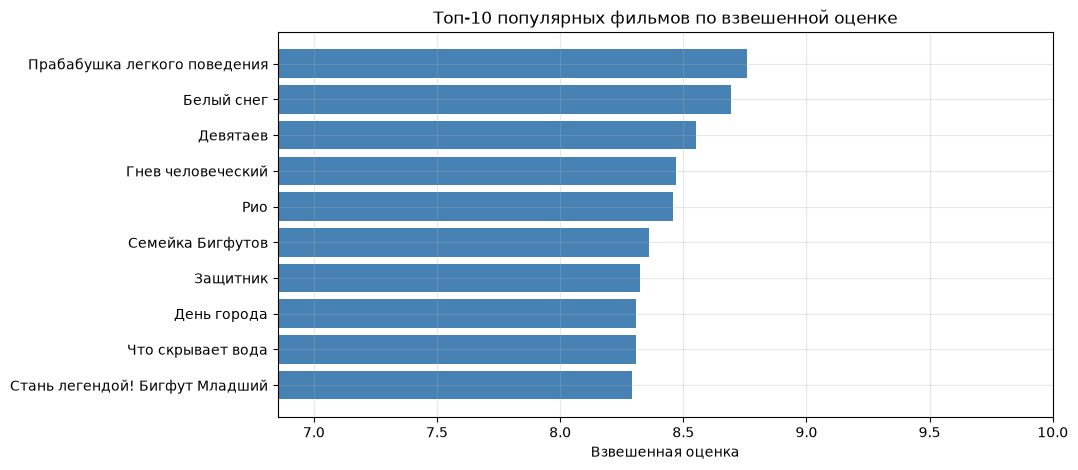

In [32]:
# график топ-10
plot_top = top10.sort_values('score')

plt.figure(figsize=(10, 5))
plt.barh(plot_top['title'], plot_top['score'], color='steelblue')
plt.title('Топ-10 популярных фильмов по взвешенной оценке')
plt.xlabel('Взвешенная оценка')
plt.xlim(C - 0.5, 10)
plt.grid(True, alpha=0.3)
plt.show()

Общая средняя оценка C = 7.35, порог m = 88 оценок. На первом месте «Прабабушка легкого поведения»: средняя 8.86 при 1 172 оценках. «Рио» со средней 9.15 только на 5 месте: у него всего 141 оценка, и взвешенная оценка тянет его к общей средней. Почти весь топ состоит из фильмов 2021 года, это новинки сервиса за период датасета.

### 3.2 Матрица оценок

Для коллаборативной фильтрации собираем матрицу пользователь на фильм. На пересечении оценка, 0 значит, что пользователь фильм не смотрел. Порядок фильмов такой же, как в `movies_clean`.

In [33]:
# матрица пользователь-фильм
movie_ids = movies_clean['movie_id'].tolist()


def build_matrix(df):
    table = df.pivot_table(index='user_id', columns='movie_id', values='rating')
    table = table.reindex(columns=movie_ids).fillna(0)
    return table.index.tolist(), table.to_numpy(dtype=np.float32)


user_ids, R = build_matrix(ratings)
print("Размер матрицы:", R.shape)
print(f"Заполнено: {(R > 0).mean() * 100:.2f}%")

Размер матрицы: (4000, 1734)
Заполнено: 1.96%


Матрица 4 000 пользователей на 1 734 фильма заполнена на 1.96%: в среднем пользователь смотрел около 34 фильмов из выборки.

### 3.3 Коллаборативная фильтрация по фильмам

Каждый фильм описываем столбцом оценок всех пользователей. Из оценок вычитаем среднюю оценку фильма и сравниваем столбцы косинусным сходством. Без вычитания похожими друг на друга оказываются просто фильмы, которые все досматривают. Сравниваем только фильмы, которые смотрели не меньше 10 общих пользователей.

In [34]:
# сходство фильмов по оценкам
def item_similarity(R):
    seen = R > 0
    counts = seen.sum(axis=0)
    item_means = np.divide(R.sum(axis=0), counts, out=np.zeros(R.shape[1], dtype=np.float32), where=counts > 0)
    centered = np.where(seen, R - item_means, 0)
    norms = np.linalg.norm(centered, axis=0)
    centered = np.divide(centered, norms, out=np.zeros_like(centered), where=norms > 0)
    sim = centered.T @ centered
    common = seen.T.astype(np.float32) @ seen.astype(np.float32)
    return sim, common, item_means


item_sim, common, item_means = item_similarity(R)
print("Размер матрицы сходства фильмов:", item_sim.shape)

Размер матрицы сходства фильмов: (1734, 1734)


In [35]:
# пример: фильм, который смотрели чаще всего
example_movie = ratings['movie_id'].value_counts().index[0]
pos = movie_ids.index(example_movie)
print("Фильм:", movies_clean.loc[pos, 'title'], movies_clean.loc[pos, 'year'], movies_clean.loc[pos, 'genres'])

scores = item_sim[pos].copy()
scores[pos] = -1
scores[common[pos] < 10] = -1
best = np.argsort(-scores)[:10]
movies_clean.loc[best, ['title', 'year', 'genres']].assign(сходство=scores[best].round(3), общих_зрителей=common[pos, best].astype(int))

Фильм: Гнев человеческий 2021 боевики, триллеры


,title,year,genres,сходство,общих_зрителей
1622,Дочь волка,2019,"боевики, триллеры",0.089,402
795,Последний богатырь: Корень зла,2021,"семейное, фэнтези, приключения, комедии",0.081,33
925,Стендап под прикрытием,2020,комедии,0.076,235
697,Девятаев,2021,"драмы, военные, приключения",0.076,887
1675,Денежная игла,2021,триллеры,0.075,305
654,"Значит, война",2012,"боевики, мелодрамы, комедии",0.071,65
1041,Цвет из иных миров,2020,"фантастика, ужасы",0.069,248
786,Злодей,2020,"боевики, драмы, триллеры",0.069,84
689,Бомж с дробовиком,2011,"боевики, триллеры, криминал",0.065,26
999,Доспехи бога: в поисках сокровищ,2016,"приключения, детективы, боевики, фэнтези, комедии",0.064,44


Самый просматриваемый фильм в выборке «Гнев человеческий». Похожие по оценкам: «Дочь волка» (тоже боевик и триллер, 402 общих зрителя), «Денежная игла», «Девятаев». Сходство небольшое (0.06-0.09): матрица почти пустая, а оценки в основном 10 или 1-2. В список попадают и фильмы других жанров (комедия «Стендап под прикрытием»): их смотрели те же люди, коллаборативная фильтрация смотрит на поведение, а не на жанр.

### 3.4 Коллаборативная фильтрация по пользователям

Каждого пользователя описываем строкой его оценок. Из оценок вычитаем его среднюю оценку: так учитываем, что кто-то досматривает всё подряд, а кто-то бросает почти каждый фильм. Сходство двух пользователей считаем косинусом по общим фильмам и умножаем на $n / (n + 10)$, где $n$ число общих фильмов. Поправка уменьшает сходство, когда общих фильмов мало.

In [36]:
# сходство пользователей по оценкам
def user_similarity(R):
    seen = (R > 0).astype(np.float32)
    counts = seen.sum(axis=1)
    user_means = R.sum(axis=1) / counts
    centered = np.where(R > 0, R - user_means[:, None], 0).astype(np.float32)
    numerator = centered @ centered.T
    squares = (centered ** 2) @ seen.T
    denominator = np.sqrt(squares * squares.T)
    sim = np.divide(numerator, denominator, out=np.zeros_like(numerator), where=denominator > 0)
    overlap = seen @ seen.T
    sim = sim * overlap / (overlap + 10)
    np.fill_diagonal(sim, 0)
    return sim, centered, user_means


user_sim, centered, user_means = user_similarity(R)
print("Размер матрицы сходства пользователей:", user_sim.shape)

Размер матрицы сходства пользователей: (4000, 4000)


In [37]:
# пример: пользователь с 50 и больше оценками, у которого средняя ближе всего к общей
user_stats = ratings.groupby('user_id')['rating'].agg(['mean', 'count'])
active_stats = user_stats[user_stats['count'] >= 50]
example_user = int((active_stats['mean'] - C).abs().idxmin())
u = user_ids.index(example_user)
overlap = ((R > 0) & (R[u] > 0)).sum(axis=1)
nearest = np.argsort(-user_sim[u])[:5]

print(f"Пользователь {example_user}: оценок {(R[u] > 0).sum()}, средняя оценка {user_means[u]:.2f}")
pd.DataFrame({
    'user_id': [user_ids[i] for i in nearest],
    'сходство': user_sim[u, nearest].round(3),
    'общих фильмов': overlap[nearest],
    'средняя оценка': user_means[nearest].round(2)
})

Пользователь 1642: оценок 62, средняя оценка 7.35


,user_id,сходство,общих фильмов,средняя оценка
0,2147,0.412,7,8.35
1,1158,0.411,14,6.44
2,2592,0.405,8,8.00
3,1943,0.396,8,7.93
4,3615,0.393,7,8.56


Для примера взяли пользователя 1642: 62 оценки и средняя 7.35, как у всей выборки. У самых похожих на него сходство около 0.4 при 7-14 общих фильмах. Средние оценки соседей разные (от 6.44 до 8.56), но после вычитания средней это не мешает: сравниваются отклонения от своей средней.

### 3.5 Рекомендации по контенту

Фильм описываем двумя векторами TF-IDF: по подготовленному описанию и по жанрам (каждый жанр как отдельное слово). Слово получает больший вес, если часто встречается в описании этого фильма и редко в остальных. Сходство фильмов считаем косинусом, итог: 70% сходства описаний и 30% сходства жанров. Если брать только жанры, у фильмов с одинаковым набором жанров сходство 100%, и топ-10 был бы набором случайных фильмов того же жанра.

In [38]:
# импорт библиотек
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [39]:
# вектора TF-IDF по описаниям и жанрам
text_vectorizer = TfidfVectorizer(min_df=2, max_df=0.5, sublinear_tf=True)
text_tfidf = text_vectorizer.fit_transform(movies_clean['text'])

genre_vectorizer = TfidfVectorizer(tokenizer=lambda s: s.split(', '), token_pattern=None, lowercase=False)
genre_tfidf = genre_vectorizer.fit_transform(movies_clean['genres'])

content_sim = 0.7 * cosine_similarity(text_tfidf) + 0.3 * cosine_similarity(genre_tfidf)
np.fill_diagonal(content_sim, -1)
print("Слов в словаре описаний:", len(text_vectorizer.vocabulary_))
print("Жанров:", len(genre_vectorizer.vocabulary_))

Слов в словаре описаний: 6405
Жанров: 29


In [40]:
# 10 похожих по контенту на тот же фильм
best_content = np.argsort(-content_sim[pos])[:10]
print("Фильм:", movies_clean.loc[pos, 'title'])
movies_clean.loc[best_content, ['title', 'year', 'genres']].assign(сходство=content_sim[pos, best_content].round(3))

Фильм: Гнев человеческий


,title,year,genres,сходство
236,Ледяной драйв,2021,"боевики, триллеры",0.360
383,Овердрайв,2017,"боевики, триллеры",0.341
701,Заложница 3,2014,"боевики, триллеры",0.332
650,Код бессмертия,2019,"боевики, триллеры",0.327
1336,Последняя пуля,2020,боевики,0.326
1683,Экспат,2011,"боевики, триллеры",0.325
372,Воздушный охотник,1999,"боевики, триллеры",0.324
282,Тройная угроза,2019,"боевики, триллеры",0.324
1190,Неистовый,2020,"боевики, триллеры",0.322
692,Перевозчик 2,2005,"боевики, триллеры",0.321


В словаре 6 405 слов и 29 жанров. Для «Гнева человеческого» все 10 похожих боевики, 9 из них ещё и триллеры. Сходство около 0.32-0.36. У этого фильма короткое описание, поэтому порядок сильнее задают жанры, а описание выбирает среди фильмов того же жанра («Ледяной драйв», «Заложница 3», «Перевозчик 2»).

In [41]:
# проверка гипотезы 2: берём 10 похожих только по описанию, без жанров,
# и смотрим, у какой доли есть общий жанр с исходным фильмом
genre_sets = movies_clean['genres'].str.split(', ').apply(set)
text_sim = cosine_similarity(text_tfidf)
np.fill_diagonal(text_sim, -1)
top_text = np.argsort(-text_sim, axis=1)[:, :10]
share_text = np.mean([len(genre_sets[i] & genre_sets[j]) > 0 for i in range(len(movies_clean)) for j in top_text[i]])

rng = np.random.default_rng(42)
random_pairs = rng.integers(0, len(movies_clean), size=(20000, 2))
share_random = np.mean([len(genre_sets[i] & genre_sets[j]) > 0 for i, j in random_pairs])

print(f"С общим жанром среди 10 похожих по описанию: {share_text * 100:.1f}%")
print(f"С общим жанром у случайной пары фильмов: {share_random * 100:.1f}%")

С общим жанром среди 10 похожих по описанию: 65.7%
С общим жанром у случайной пары фильмов: 48.4%


Среди 10 фильмов, похожих только по описанию, общий жанр с исходным есть у 65.7%, а у случайной пары фильмов у 48.4%. Описание само по себе находит фильмы того же жанра заметно чаще случайного, гипотеза 2 подтверждается.

### 3.6 Персональные рекомендации

Считаем прогноз для фильмов, которые пользователь ещё не смотрел. Для каждого фильма нужны хотя бы 3 соседа. Используем два способа:

1. По похожим пользователям: берём до 30 похожих пользователей, которые смотрели фильм. К средней оценке пользователя прибавляем взвешенное отклонение оценок соседей от их средних.
2. По похожим фильмам: берём до 30 похожих фильмов из истории пользователя. К средней оценке выбранного фильма прибавляем взвешенное отклонение его оценок от средних по этим фильмам.

Оба прогноза могут выйти за шкалу 1-10. После обрезки оценки скапливаются у 10. Сглаживаем прогноз средним из двух значений: средней оценки фильма и средней оценки пользователя. Соседи получают вес по их числу. Вес среднего взяли равным минимальному числу соседей, то есть 3. При 3 соседях веса равны, при 30 соседях исходный прогноз даёт около 91% результата. Сортируем по сглаженному прогнозу.

In [42]:
# прогноз по похожим пользователям
def predict_user_based(u, R, user_sim, centered, user_means, cols, k=30):
    sim = user_sim[u]
    order = np.argsort(-sim, kind='stable')
    order = order[sim[order] > 0]
    sim_sorted = sim[order]
    seen_sorted = R[np.ix_(order, cols)] > 0
    top_k = seen_sorted & (np.cumsum(seen_sorted, axis=0) <= k)
    weights = top_k * sim_sorted[:, None]
    numerator = (weights * centered[np.ix_(order, cols)]).sum(axis=0)
    denominator = weights.sum(axis=0)
    shift = np.divide(numerator, denominator, out=np.zeros_like(numerator), where=denominator > 0)
    return user_means[u] + shift, top_k.sum(axis=0)

In [43]:
# прогноз по похожим фильмам
def predict_item_based(u, R, item_sim, common, item_means, cols, k=30):
    rated = np.flatnonzero(R[u] > 0)
    weights = item_sim[np.ix_(cols, rated)]
    weights[(weights < 0) | (common[np.ix_(cols, rated)] < 10)] = 0
    # для каждого фильма оставляем k самых похожих из оценённых
    if len(rated) > k:
        outside_top = np.argsort(-weights, axis=1, kind='stable')[:, k:]
        np.put_along_axis(weights, outside_top, 0, axis=1)
    deviations = R[u, rated] - item_means[rated]
    denominator = weights.sum(axis=1)
    shift = np.divide(weights @ deviations, denominator, out=np.zeros_like(denominator), where=denominator > 0)
    return item_means[cols] + shift, (weights > 0).sum(axis=1)

In [44]:
# сглаживание прогноза
def smooth_predictions(pred, n_used, item_means, user_mean):
    prior = (item_means + user_mean) / 2
    return (n_used * np.clip(pred, 1, 10) + 3 * prior) / (n_used + 3)

In [45]:
# что пользователь уже смотрел и оценил выше всего
watched = np.flatnonzero(R[u] > 0)
best_watched = watched[np.argsort(-R[u, watched])][:5]
movies_clean.loc[best_watched, ['title', 'year', 'genres']].assign(оценка=R[u, best_watched].astype(int))

,title,year,genres,оценка
1532,Форма воды,2017,"драмы, фантастика, мелодрамы",10
630,Что скрывает вода,2020,"ужасы, триллеры",10
1256,Амулет,2020,"ужасы, фэнтези",10
1493,Защитник,2015,"драмы, триллеры, детективы",10
743,Персональный покупатель,2016,"драмы, триллеры, детективы",10


In [46]:
# топ-10 для пользователя двумя способами
cols = np.arange(len(movie_ids))
pred_users, n_users = predict_user_based(u, R, user_sim, centered, user_means, cols)
pred_items, n_items = predict_item_based(u, R, item_sim, common, item_means, cols)

for name, pred, n_used in [('По похожим пользователям', pred_users, n_users), ('По похожим фильмам', pred_items, n_items)]:
    allowed = np.flatnonzero((R[u] == 0) & (n_used >= 3))
    before = allowed[np.argsort(-pred[allowed], kind='stable')[:10]]
    pred_smooth = smooth_predictions(pred, n_used, item_means, user_means[u])
    order = allowed[np.argsort(-pred_smooth[allowed], kind='stable')[:10]]
    tens_before = (np.clip(pred[before], 1, 10).round(2) == 10).sum()
    tens_after = (pred_smooth[order].round(2) == 10).sum()
    print(f"{name}. Десяток до сглаживания: {tens_before}, после: {tens_after}")
    display(movies_clean.loc[order, ['title', 'year', 'genres']].assign(
        прогноз=pred_smooth[order].round(2), соседей=n_used[order]))

По похожим пользователям. Десяток до сглаживания: 3, после: 0


,title,year,genres,прогноз,соседей
438,Улыбка,2019,комедии,9.79,17
594,"Ишь ты, масленица",1985,мультфильм,9.74,12
1114,"В синем море, в белой пене",1984,"семейное, мультфильм",9.59,15
1673,Погружение,2019,комедии,9.56,18
262,В объятиях лжи,2018,"драмы, триллеры, детективы",9.42,14
45,Убийство в Восточном экспрессе,2017,"драмы, криминал, детективы",9.42,30
199,Мама для мамонтенка,1981,мультфильм,9.37,14
1277,Жить,2010,"драмы, триллеры, криминал",9.36,14
1672,Невеста,2017,"ужасы, триллеры",9.35,9
211,Мой батальон,2016,"драмы, военные",9.32,12


По похожим фильмам. Десяток до сглаживания: 10, после: 0


,title,year,genres,прогноз,соседей
688,День города,2021,комедии,9.80,30
434,Обратная связь,2020,комедии,9.63,20
810,Белый снег,2021,"драмы, спорт",9.61,30
1341,13,2010,"драмы, триллеры",9.59,14
1528,На пятьдесят оттенков темнее,2017,"драмы, мелодрамы",9.57,14
382,На крючке,2011,"мелодрамы, комедии",9.48,10
832,Предложение (2009),2009,"драмы, мелодрамы, комедии",9.41,9
110,Хищник,1987,"боевики, фантастика, триллеры, приключения",9.41,9
744,"День, когда Земля остановилась",2008,"драмы, фантастика, триллеры",9.39,13
785,Сделано в Италии,2020,комедии,9.34,14


Для пользователя 1642 до сглаживания в топах было 3 десятки по похожим пользователям и 10 по фильмам. После сглаживания прогнозы в обоих топах лежат от 9.32 до 9.80.

### 3.7 Метрики качества

Проверяем прогноз на тех же спрятанных 20% оценок. Сходства и средние считаем по обучающей части.

1. MAE: средняя абсолютная ошибка в баллах.
2. RMSE: корень из средней квадратичной ошибки, сильнее учитывает большие промахи.
3. Покрытие: доля тестовых оценок, для которых метод дал прогноз. Как в приложении, у пользователя должно быть минимум 3 оценки и хотя бы две разные. Для фильма нужно хотя бы 3 соседа.

Сравниваем среднюю оценку фильма, оба способа без сглаживания и те же способы со сглаживанием. Если метод не дал прогноз, для подсчёта ошибки используем среднюю оценку фильма. Отдельно проверяем, как часто в топ-10 встречается 10 после округления, по 200 случайным профилям Kion.

In [47]:
# все матрицы заново только по обучающей части
train_users, R_train = build_matrix(train)
item_sim_tr, common_tr, item_means_tr = item_similarity(R_train)
user_sim_tr, centered_tr, user_means_tr = user_similarity(R_train)
user_pos = {user_id: i for i, user_id in enumerate(train_users)}
movie_pos = {movie_id: i for i, movie_id in enumerate(movie_ids)}

In [48]:
# прогноз для каждой оценки из теста
rows = []
for user_id, group in test.groupby('user_id'):
    u_tr = user_pos[user_id]
    cols = group['movie_id'].map(movie_pos).to_numpy()
    baseline = item_means_tr[cols]
    p_users, n_u = predict_user_based(u_tr, R_train, user_sim_tr, centered_tr, user_means_tr, cols)
    p_items, n_i = predict_item_based(u_tr, R_train, item_sim_tr, common_tr, item_means_tr, cols)
    p_users_smooth = smooth_predictions(p_users, n_u, baseline, user_means_tr[u_tr])
    p_items_smooth = smooth_predictions(p_items, n_i, baseline, user_means_tr[u_tr])
    profile_ratings = R_train[u_tr][R_train[u_tr] > 0]
    has_profile = len(profile_ratings) >= 3 and profile_ratings.min() != profile_ratings.max()
    user_ok = has_profile & (n_u >= 3)
    item_ok = has_profile & (n_i >= 3)
    rows.append(pd.DataFrame({
        'rating': group['rating'].to_numpy(),
        'baseline': baseline,
        'users_before': np.where(user_ok, p_users, baseline),
        'items_before': np.where(item_ok, p_items, baseline),
        'users_after': np.where(user_ok, p_users_smooth, baseline),
        'items_after': np.where(item_ok, p_items_smooth, baseline),
        'user_ok': user_ok,
        'item_ok': item_ok
    }))
pred_test = pd.concat(rows, ignore_index=True)
print(f"Прогнозов: {len(pred_test):,}")

Прогнозов: 27,233


In [49]:
# импорт библиотек
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [50]:
# таблица метрик
methods = [
    ('Средняя оценка фильма', 'baseline', 100),
    ('По пользователям без сглаживания', 'users_before', pred_test['user_ok'].mean() * 100),
    ('По пользователям со сглаживанием', 'users_after', pred_test['user_ok'].mean() * 100),
    ('По фильмам без сглаживания', 'items_before', pred_test['item_ok'].mean() * 100),
    ('По фильмам со сглаживанием', 'items_after', pred_test['item_ok'].mean() * 100)
]
results = []
for name, column, coverage in methods:
    pred = pred_test[column].clip(1, 10)
    results.append({
        'Метод': name,
        'MAE': mean_absolute_error(pred_test['rating'], pred),
        'RMSE': np.sqrt(mean_squared_error(pred_test['rating'], pred)),
        'Покрытие, %': coverage
    })
df_metrics = pd.DataFrame(results).set_index('Метод')
df_metrics.round(2)

,MAE,RMSE,"Покрытие, %"
Метод,,,
Средняя оценка фильма,2.90,3.32,100.00
По пользователям без сглаживания,2.55,3.15,99.20
По пользователям со сглаживанием,2.57,3.12,99.20
По фильмам без сглаживания,2.68,3.29,57.71
По фильмам со сглаживанием,2.70,3.22,57.71


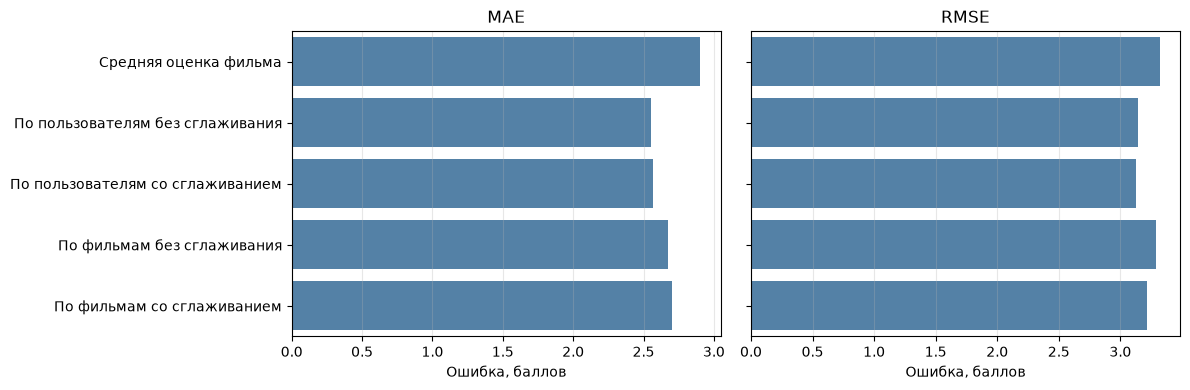

In [51]:
# сравнение mae и rmse
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, metric in zip(axes, ['MAE', 'RMSE']):
    sns.barplot(x=df_metrics[metric], y=df_metrics.index, color='steelblue', ax=ax)
    ax.set_title(metric)
    ax.set_xlabel('Ошибка, баллов')
    ax.set_ylabel('')
    ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

На 27 233 тестовых оценках сглаживание уменьшило RMSE с 3.15 до 3.12 по пользователям и с 3.29 до 3.22 по фильмам. MAE у обоих методов выросла на 0.02 балла. Оба сглаженных прогноза точнее средней оценки фильма (MAE 2.90 и RMSE 3.32), гипотеза 3 подтверждается.

У способа по пользователям покрытие 99.20%, у способа по фильмам 57.71%. Второму часто не хватает похожих фильмов в истории пользователя.

In [52]:
# доля десяток в топ-10 для 200 случайных пользователей
sample_users = np.random.default_rng(42).choice(len(user_ids), size=200, replace=False)
cols = np.arange(len(movie_ids))
top_rows = []
for user in sample_users:
    profile_ratings = R[user][R[user] > 0]
    if len(profile_ratings) < 3 or profile_ratings.min() == profile_ratings.max():
        continue
    p_users, n_u = predict_user_based(user, R, user_sim, centered, user_means, cols)
    p_items, n_i = predict_item_based(user, R, item_sim, common, item_means, cols)
    for name, pred, counts in [('По пользователям', p_users, n_u), ('По фильмам', p_items, n_i)]:
        allowed = np.flatnonzero((R[user] == 0) & (counts >= 3))
        pred_smooth = smooth_predictions(pred, counts, item_means, user_means[user])
        for version, scores in [('Без сглаживания', pred), ('Со сглаживанием', pred_smooth)]:
            best = allowed[np.argsort(-scores[allowed], kind='stable')[:10]]
            tens = (np.clip(scores[best], 1, 10).round(2) == 10).sum()
            top_rows.append((name, version, len(best), tens))

top_stats = pd.DataFrame(top_rows, columns=['Метод', 'Вариант', 'Прогнозов в топах', 'Десяток'])
top_stats = top_stats.groupby(['Метод', 'Вариант']).sum()
top_stats['Доля десяток, %'] = top_stats['Десяток'] / top_stats['Прогнозов в топах'] * 100
top_stats.round(2)

Прогнозов в топах  Десяток  Доля десяток, %
Метод            Вариант                                                     
По пользователям Без сглаживания               1990     1162            58.39
                 Со сглаживанием               1990        0             0.00
По фильмам       Без сглаживания               1990     1558            78.29
                 Со сглаживанием               1990        0             0.00

Подборки получили 199 из 200 профилей. В их топах до сглаживания было 58.39% десяток по похожим пользователям и 78.29% по похожим фильмам. После сглаживания из 1 990 прогнозов каждого метода ни один не округлился до 10.

### 3.8 Итог по методам

1. Для топ-10 популярных берём взвешенную оценку, она не даёт подняться фильмам с парой оценок.
2. Для похожих фильмов делаем два способа: по оценкам (коллаборативная фильтрация по фильмам) и по контенту (описание 70%, жанры 30%).
3. Для персональных рекомендаций по умолчанию используем сглаженный прогноз по похожим пользователям. У него RMSE 3.12 и покрытие 99.20%. Способ по похожим фильмам доступен в том же разделе.

## Этап 4. API и приложение

Код из ноутбука перенесён в `app/recommender.py`, расчёты там те же. API на FastAPI (`app/main.py`) отдаёт списки по пунктам задания:

| Пункт задания | Команда API |
|---|---|
| 1. Топ-10 популярных | `GET /api/popular?limit=10` |
| 2. Коллаборативная фильтрация по фильмам | `GET /api/movies/{movie_id}/similar-by-ratings` |
| 2. Коллаборативная фильтрация по пользователям | `GET /api/users/{user_id}/neighbors` |
| 3. 10 фильмов по контенту | `GET /api/movies/{movie_id}/similar` |
| 4. Персональные рекомендации | `GET /api/users/{user_id}/recommendations?method=users` или `method=items` |
| Оценить фильм | `POST /api/ratings` |

Каталог и оценки хранятся в базе SQLite `data/recommender.sqlite3`. Новая оценка из приложения сохраняется в базу и сразу учитывается в расчётах.

В приложении на Streamlit сначала выбираем ID пользователя. Дальше можно смотреть рекомендации, сменить профиль, найти фильм и поставить оценку со своего ID. Разделы находятся в левом меню. Команды API и параметры перечислены в разделе «Справка».

## Итоги

1. Взяли Kion: 15 963 фильма и сериала в каталоге с русскими описаниями и 5 476 251 просмотр. Баллы от 1 до 10 получили из доли просмотра.
2. После отбора осталось 1 734 фильма, 4 000 пользователей и 136 161 балл.
3. Сделали топ-10 популярных, коллаборативную фильтрацию по фильмам и по пользователям, 10 похожих по контенту и персональные рекомендации.
4. В проверенных топах после сглаживания десяток не было. У способа по похожим пользователям RMSE снизилась с 3.15 до 3.12, а MAE выросла с 2.55 до 2.57.
5. Приложение открывается с выбора пользователя. Свои оценки сохраняются в SQLite и учитываются в рекомендациях.